# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos de dato:\n", df.dtypes.value_counts())
print("\nNulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

print("\nDistribución de target:")
dist = df["target"].value_counts().sort_index()
print(pd.DataFrame({"n": dist, "proporción": (dist / len(df)).round(3)}))

print("\nRangos (min / max) de algunas variables, para ver diferencias de escala:")
print(df[["hue", "alcohol", "magnesium", "proline"]].agg(["min", "max"]).T)

# Posibles valores atípicos por regla del IQR (solo informativo; no se eliminan)
q1, q3 = df.drop(columns="target").quantile(0.25), df.drop(columns="target").quantile(0.75)
iqr = q3 - q1
outliers = ((df.drop(columns="target") < q1 - 1.5 * iqr) | (df.drop(columns="target") > q3 + 1.5 * iqr)).sum()
print("\nValores fuera de 1.5*IQR por variable (solo las que tienen):")
print(outliers[outliers > 0])

Forma: (178, 14)

Tipos de dato:
 float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Filas duplicadas: 0

Distribución de target:
         n  proporción
target                
0       59       0.331
1       71       0.399
2       48       0.270

Rangos (min / max) de algunas variables, para ver diferencias de escala:
              min      max
hue          0.48     1.71
alcohol     11.03    14.83
magnesium   70.00   162.00
proline    278.00  1680.00

Valores fuera de 1.5*IQR por variable (solo las que tienen):
malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1
dtype: int64


**Conclusión de calidad:**

> **Qué encontré:** el dataset tiene **178 filas y 13 variables numéricas** (todas `float64`) más el `target` (`int64`, 3 clases). **No hay nulos ni filas duplicadas.** Las clases están moderadamente desbalanceadas (clase 0: 33.1 %, clase 1: 39.9 %, clase 2: 27.0 %). Las variables tienen escalas muy distintas (`hue` entre 0.48 y 1.71 frente a `proline` entre 278 y 1680). Por la regla del IQR aparecen unos pocos valores atípicos (entre 1 y 4) en 7 variables.
>
> **Decisiones:** no hace falta limpiar datos. **No eliminé los atípicos**: son pocos, el dataset es pequeño y no hay evidencia de errores de captura (son mediciones químicas). Usé un **split estratificado** para conservar las proporciones de clase en train y test. Dejé el imputador por mediana dentro del pipeline como salvaguarda para datos nuevos, y como las escalas difieren mucho, los modelos sensibles a la escala necesitarán estandarización.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

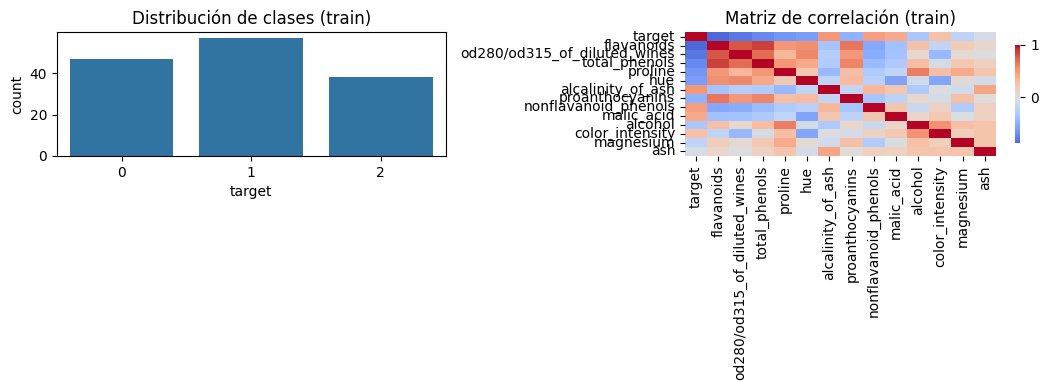

Variables más discriminativas (F de ANOVA, solo train):
flavanoids                      224.8
proline                         161.5
od280/od315_of_diluted_wines    144.8
color_intensity                 103.9
alcohol                          98.5
hue                              79.5
dtype: float64


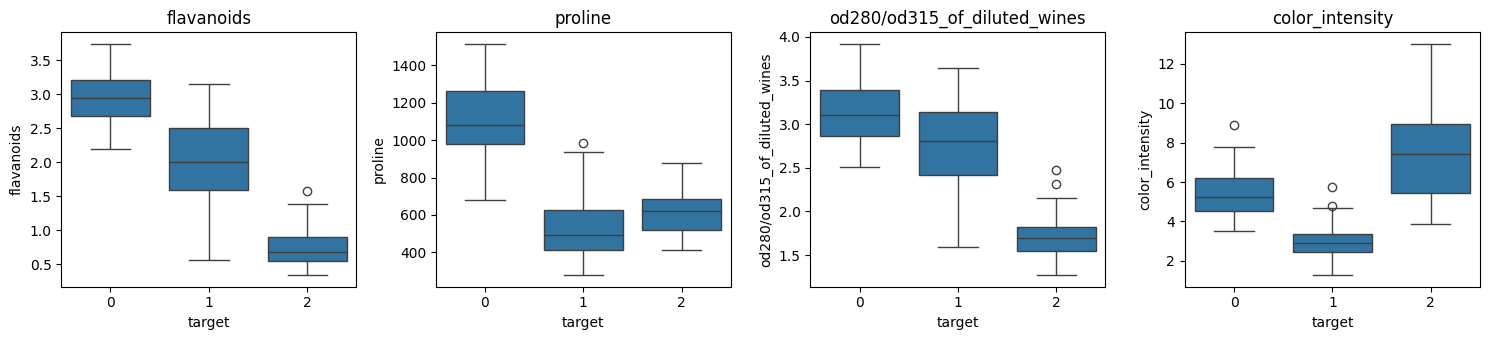


Pares más correlacionados entre variables (|r|):
total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.69
flavanoids     proanthocyanins                 0.66
dtype: float64

Medias por clase de variables con escalas muy distintas (train):
        proline  flavanoids  color_intensity   hue
target                                            
0       1092.34        2.93             5.48  1.05
1        526.25        2.01             2.98  1.05
2        622.89        0.78             7.39  0.68


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1) Distribución de clases
sns.countplot(x="target", data=train_df, ax=axes[0])
axes[0].set_title("Distribución de clases (train)")

# 2) Correlación con el target y entre variables
corr = train_df.corr()
order = corr["target"].abs().sort_values(ascending=False).index
sns.heatmap(train_df[order].corr(), cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title("Matriz de correlación (train)")
plt.tight_layout(); plt.show()

# 3) Boxplots de las variables más discriminativas (ANOVA F calculado solo con train)
from sklearn.feature_selection import f_classif
features = [c for c in train_df.columns if c != "target"]
F, _ = f_classif(train_df[features], train_df["target"])
top = pd.Series(F, index=features).sort_values(ascending=False)
print("Variables más discriminativas (F de ANOVA, solo train):")
print(top.round(1).head(6))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, top.index[:4]):
    sns.boxplot(x="target", y=col, data=train_df, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Pares de variables muy correlacionadas
c = train_df[features].corr().abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("\nPares más correlacionados entre variables (|r|):")
print(pairs.head(4).round(2))

print("\nMedias por clase de variables con escalas muy distintas (train):")
print(train_df.groupby("target")[["proline", "flavanoids", "color_intensity", "hue"]].mean().round(2))

**Hallazgos:**

1. **Las clases se separan bien con pocas variables.** Las más discriminativas (F de ANOVA en train) son `flavanoids` (224.8), `proline` (161.5), `od280/od315` (144.8) y `color_intensity` (103.9). Por ejemplo, la clase 2 tiene `flavanoids` bajo (0.78 vs 2.93 y 2.01) y `hue` bajo (0.68 vs 1.05), la clase 0 tiene `proline` alta (1092 vs 526 y 623) y la clase 1 tiene baja `color_intensity` (2.98). Es esperable un buen desempeño de casi cualquier modelo.
2. **Hay variables muy correlacionadas entre sí:** `total_phenols`–`flavanoids` (r = 0.86) y `flavanoids`–`od280/od315` (r = 0.79). Esto puede afectar la interpretación de los coeficientes de la regresión logística (multicolinealidad) y hace recomendable regularizar (parámetro `C`); a los árboles y a KNN les afecta menos.
3. **Las escalas son muy distintas** (`proline` llega a 1680 y `hue` ronda 1). Para KNN (usa distancias) y regresión logística hay que **estandarizar**; los árboles no lo necesitan. Además, como hay un desbalance moderado, conviene usar CV estratificada y mirar también F1 macro, no solo accuracy.

## 4. Persistencia de datos y contrato

In [8]:
train_out = train_df.reset_index(drop=True)
test_out = test_df.reset_index(drop=True)
train_out.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")
print("Guardado:", train_out.shape, test_out.shape, "y", len(contract["features"]), "features en el contrato")

Guardado: (142, 14) (36, 14) y 13 features en el contrato


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.